<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/Ramps_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory analysis of irradiance ramps

Before training forecasting models, we study the irradiance data with a focus on ramps, i.e. sudden changes in irradiance. The aim is to understand how often ramps occur, how large and how long they are, whether they are real changes in sunlight, and how predictable they are from the past. These results guide the choices in the forecasting study: the time resolution, the ramp threshold and the input features.

We use the 1-s data of the 11 complete days (16–26 Feb 2013), daylight only. We suppose the site is Sohar University, Oman (24.30° N, 56.78° E), with timestamps in local time (UTC+4); this was checked against a clear-sky model.

Step 1: daily overview

Goal: see each day next to its clear-sky curve, and measure how cloudy it really was using the clear-sky index (measured ÷ clear-sky). An index of 1 means clear sun, below 1 means the sun is (partly) blocked, and above 1 means cloud enhancement: extra light reflected from cloud edges.

Cell 1: load the data and add the clear-sky index

In [ ]:
!pip install -q pvlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib

In [ ]:


plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ---- Load: 1-s data, complete days, daylight only ----
df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])
df.head(5)

,Solar_Rad,Solar_Rad_clean,Amb_Tempr,Tempr_PV_1,Tempr_PV_2,Tempr_PV_3,PV_1_SA_V,PV_2_GT_I,PV_4_Hor_V,PV_4_Hor_I,PV_4_Hor_P,PV4_state,full_day,daylight
DateTime,,,,,,,,,,,,,,
2013-02-15 18:49:44,2.437606,0.0,20.922115,13.257263,12.494228,13.441733,0.0,-0.009259,-0.617625,-0.086931,0.053691,night,False,False
2013-02-15 18:49:45,2.468246,0.0,20.897755,13.254468,12.499819,13.450118,0.0,-0.008453,-0.617625,-0.084999,0.052498,night,False,False
2013-02-15 18:49:46,2.468246,0.0,20.897755,13.254468,12.499819,13.450118,0.0,-0.008453,-0.617625,-0.084999,0.052498,night,False,False
2013-02-15 18:49:48,2.560166,0.0,20.922115,13.254468,12.505408,13.458504,0.0,-0.007647,-0.617625,-0.083453,0.051543,night,False,False
2013-02-15 18:49:49,2.652086,0.0,20.934296,13.262854,12.505408,13.458504,0.0,-0.007244,-0.617625,-0.083839,0.051781,night,False,False


### Data preparation

1. **Data selection.** We keep the 11 complete days (16–26 Feb) and only daylight records, at 1-s resolution. Irradiance is renamed $G$ (W/m²).

2. **Sun position.** From the site location (Sohar University, Oman; latitude $\varphi$ = 24.30° N, longitude 56.78° E) and the local time (UTC+4), pvlib computes the sun elevation $\alpha$ at every second, i.e. how high the sun is above the horizon:

$$\sin\alpha = \sin\varphi \,\sin\delta + \cos\varphi \,\cos\delta \,\cos h$$

where $\delta$ is the solar declination (depends on the day of the year) and $h$ is the hour angle (depends on the time of day; $h = 0$ at solar noon).

3. **Clear-sky irradiance.** From the same location and times, pvlib's `get_clearsky` (Ineichen model) gives the irradiance a cloud-free sky would produce, $G_{clear}$. In simplified form:

$$G_{clear} = a_1 \, I_0 \, \sin\alpha \; e^{-a_2 \, AM \,(f_{h1} + f_{h2}\,(T_L - 1))}$$

where $I_0$ is the solar irradiance outside the atmosphere, $AM$ is the air mass (the path length of sunlight through the atmosphere, longer when the sun is low), $T_L$ is the Linke turbidity (haze and water vapour; pvlib takes typical monthly values for the site), and $a_1, a_2, f_{h1}, f_{h2}$ are constants that depend on the site altitude. $G_{clear}$ follows the daily rise and fall of the sun.

4. **Clear-sky index.** We divide the measured by the clear-sky irradiance:

$$csi = \frac{G}{G_{clear}}$$

This removes the daily cycle of the sun, so only the effect of clouds remains: $csi \approx 1$ means the sun is visible, $csi < 1$ means it is blocked, and $csi > 1$ means extra light reflected from cloud edges. It is computed only when $\alpha > 10°$, because near sunrise and sunset $G_{clear}$ is very small and the ratio is not meaningful.

In [ ]:
# =====================================================================
# 1) Select the data
# =====================================================================
# full_day = True for the 11 complete days (16–26 Feb)
# daylight = True when the sun is up (nights have no irradiance and no ramps)
# Columns kept:
#   Solar_Rad_clean → irradiance after removing the sensor offset (W/m²)
#   PV_2_GT_I       → current of PV module 2, an independent sensor used later to confirm ramps
d1 = df.loc[df["full_day"] & df["daylight"], ["Solar_Rad_clean", "PV_2_GT_I"]].copy()
d1 = d1.rename(columns={"Solar_Rad_clean": "G"})          # G = usual symbol for irradiance


# =====================================================================
# 2) Sun position at every second
# =====================================================================
# Site: Sohar University, Oman (24.2979° N, 56.7803° E); timestamps in local time (Asia/Muscat, UTC+4).
# tz_localize attaches this time zone to the timestamps, which pvlib needs for the sun position.
site  = pvlib.location.Location(24.2979, 56.7803, tz="Asia/Muscat")
times = d1.index.tz_localize("Asia/Muscat")

# Sun elevation: height of the sun above the horizon in degrees (0° at sunrise/sunset)
d1["sun_elev"] = site.get_solarposition(times)["apparent_elevation"].to_numpy()


# =====================================================================
# 3) Clear-sky irradiance: what the sensor would measure with no clouds
# =====================================================================
# Ineichen = a widely used clear-sky model; ghi = global horizontal irradiance (W/m²)
d1["G_clear"] = site.get_clearsky(times, model="ineichen")["ghi"].to_numpy()


# =====================================================================
# 4) Clear-sky index (csi) = measured / clear-sky
# =====================================================================
# Removes the daily rise and fall of the sun, so only the effect of clouds remains:
#   csi ≈ 1 → sun visible      csi < 1 → sun blocked      csi > 1 → extra light from cloud edges
# Computed only when the sun is above 10°: near sunrise/sunset G_clear is very small and the
# ratio becomes meaningless. Elsewhere the value is NaN (= no value, ignored in averages).
d1["csi"] = np.where(d1["sun_elev"] > 10, d1["G"] / d1["G_clear"], np.nan)


# =====================================================================
# 5) List of days in time order (used in the next cells)
# =====================================================================
days = sorted(set(d1.index.date))
print(f"1-s daylight records: {len(d1):,}   days: {len(days)}")
display(d1.head())

1-s daylight records: 467,848   days: 11


,G,PV_2_GT_I,sun_elev,G_clear,csi
DateTime,,,,,
2013-02-16 06:38:25,0.98048,0.000816,-2.477434,0.0,NaN
2013-02-16 06:38:26,1.01112,0.000413,-2.473723,0.0,NaN
2013-02-16 06:38:27,1.01112,0.000413,-2.470012,0.0,NaN
2013-02-16 06:38:28,0.98048,0.000816,-2.466302,0.0,NaN
2013-02-16 06:38:29,0.73536,-0.000796,-2.462591,0.0,NaN


**Check of the prepared data**

- **Size:** 467,848 records over 11 days, about 11.8 h of daylight per day. This matches sunrise (≈ 06:46) and sunset (≈ 18:07) at Sohar in late February.
- **Start of each day:** the first records come a few minutes before sunrise (sun elevation −2.5° at 06:38). Irradiance is about 1 W/m², which is diffuse light from the sky at dawn.
- **Clear-sky values:** at these times $G_{clear} = 0$ and the clear-sky index is not computed, as intended.
- **PV_2 current:** close to zero at dawn (about ±0.001 A), which is small sensor noise.

### Daily statistics

To describe each day, we compute:

- **Daily energy** (kWh/m²): the total sunlight received on 1 m², i.e. the sum of the 1-s irradiance values divided by 3.6 × 10⁶.
- **Maximum irradiance vs maximum clear-sky irradiance:** measured values clearly above clear-sky indicate cloud enhancement.
- **Variability Index** (Stein et al., 2012), on 1-min averages:

$$VI = \frac{\sum_t \sqrt{(\Delta G_t)^2 + \Delta t^2}}{\sum_t \sqrt{(\Delta G_{clear,t})^2 + \Delta t^2}}, \qquad \Delta t = 1 \text{ min}$$

  It compares the length of the measured irradiance curve with that of the clear-sky curve: a smooth clear day gives $VI \approx 1$, and every up-and-down caused by clouds increases it.
- **Time with csi < 0.8** (%): the share of time when the sun was clearly blocked.

The 10-s changes of each day are also stored, for the ramp threshold in the next cell. Finally, each day gets a **type** from its VI: clear ($VI < 1.5$), few clouds ($1.5 \le VI < 5$) or broken clouds ($VI \ge 5$). These limits lie in the large gaps between the observed VI values.

### Daily statistics

**Goal:** describe each day with statistics, so we can compare the days fairly and decide which ones are clear or cloudy.

For every day we compute four things:

**1. Daily energy (kWh/m²): how much sunlight did the day give in total?**
We add up all 1-s irradiance values of the day. Because each value lasts one second, the sum is energy in J/m²; dividing by 3,600,000 converts it to kWh/m².

**2. Highest measured vs highest clear-sky irradiance: did the irradiance go above a clear sky?**
Normally a cloud can only reduce the sunlight. If the measured peak is clearly higher than the clear-sky peak, light reflected from the edges of nearby clouds added extra light (cloud enhancement).

**3. Variability Index, VI: how much did the irradiance jump up and down?**
Imagine drawing the irradiance curve of the day and measuring its length with a string. A smooth day gives a short, smooth curve. A cloudy day gives a curve full of up-and-down spikes, and the string becomes much longer. The VI is the length of the measured curve divided by the length of the clear-sky curve (Stein et al., 2012):

$$VI = \frac{\text{length of measured curve}}{\text{length of clear-sky curve}} = \frac{\sum_t \sqrt{(\Delta G_t)^2 + \Delta t^2}}{\sum_t \sqrt{(\Delta G_{clear,t})^2 + \Delta t^2}}$$

Here $\Delta G_t$ is the change in irradiance from one minute to the next, and $\Delta t$ = 1 min. Each term $\sqrt{(\Delta G)^2 + \Delta t^2}$ is the length of one short piece of the curve (Pythagoras), and the sum adds all pieces together.

*Example:* on a clear day the measured curve follows the clear-sky curve, so both have about the same length and $VI \approx 1$. On a cloudy day, a single drop from 800 to 300 W/m² and back adds a piece of about 1000 W/m² to the length, while the clear-sky curve hardly changes in that minute. Many such drops give a VI of 10 or more.

**4. Time with csi < 0.8 (%): for how much of the day was the sun clearly blocked?**
The share of time when less than 80 % of the clear-sky light reached the sensor.

**Day type.** From the VI, each day is labelled:

| Type | VI |
|---|---|
| clear | below 1.5 |
| few clouds | 1.5 to 5 |
| broken clouds | above 5 |

The limits 1.5 and 5 are placed in the two large gaps between the VI values of our days, so no day lies close to a limit.

The 10-s changes of each day are also stored; they are used to set the ramp threshold in the next cell.

In [ ]:
# =====================================================================
# Daily statistics: one row per day
# =====================================================================
#   energy          → how much sunlight the day gave in total
#   max G vs clear  → did irradiance go above the clear-sky value (cloud enhancement)?
#   VI, csi < 0.8   → how variable / cloudy the day was (used to define the day type)

rows    = []                                        # one dictionary (= one table row) per day
changes = {}                                        # 10-s changes of each day (used for the ramp threshold)

for day in days:
    g = d1[d1.index.date == day]                    # all 1-s records of this day

    # ---- 10-s averages (same resolution as the forecasting study) ----
    g10 = g[["G"]].resample("10s").mean().dropna()
    ok  = g10.index.to_series().diff() == pd.Timedelta(seconds=10)   # only real neighbouring steps (no gaps)
    changes[day] = g10["G"].diff()[ok]                               # 10-s changes of irradiance (W/m²)

    # ---- Variability Index (Stein et al., 2012), on 1-min averages as in the original paper ----
    # VI = length of the measured curve / length of the clear-sky curve.
    # sqrt(ΔG² + Δt²) = length of one small piece of the curve (Pythagoras), with Δt = 1 min.
    g1m = g[["G", "G_clear"]].resample("1min").mean().dropna()
    VI  = (np.sqrt(g1m["G"].diff().dropna() ** 2 + 1).sum()
           / np.sqrt(g1m["G_clear"].diff().dropna() ** 2 + 1).sum())

    rows.append({
        "date": day,
        # Daily energy: each record lasts 1 s and 1 W = 1 J/s → sum in J/m²; 1 kWh = 3,600,000 J
        "energy (kWh/m²)":      g["G"].sum() / 3.6e6,
        # Measured clearly above clear-sky = cloud enhancement (light reflected from cloud edges)
        "max G (W/m²)":         g["G"].max(),
        "max clear-sky (W/m²)": g["G_clear"].max(),
        # ~1 = smooth day; larger = more variable
        "VI":                   VI,
        # Share of time (%) with the sun clearly blocked (less than 80 % of clear-sky light).
        # The mean of True/False = share of True.
        "time csi < 0.8 (%)":   100 * (g["csi"].dropna() < 0.8).mean(),
    })

daily = pd.DataFrame(rows).set_index("date")

# ---- Day type from the Variability Index ----
# Sort the VI values and find the two largest gaps between neighbouring days.
# Each limit is placed in the middle of a gap (on a log scale, because VI grows by factors).
vi_sorted = np.sort(daily["VI"].to_numpy())
log_gaps  = np.diff(np.log(vi_sorted))                       # gap between each pair of neighbouring days
largest   = np.sort(np.argsort(log_gaps)[-2:])               # positions of the two largest gaps
limits    = [float(np.sqrt(vi_sorted[i] * vi_sorted[i + 1])) for i in largest]   # middle of each gap
print(f"VI limits (middle of the two largest gaps): {limits[0]:.2f} and {limits[1]:.2f}")

daily["type"] = pd.cut(daily["VI"], bins=[0, *limits, np.inf],
                       labels=["clear", "few clouds", "broken clouds"])

display(daily.sort_values("VI").round(2))           # sorted by VI, so groups and gaps are easy to see

VI limits (middle of the two largest gaps): 1.50 and 4.33


,energy (kWh/m²),max G (W/m²),max clear-sky (W/m²),VI,time csi < 0.8 (%),type
date,,,,,,
2013-02-26,5.61,828.90,835.30,1.08,0.00,clear
2013-02-19,5.40,836.59,812.63,1.10,0.00,clear
2013-02-21,5.47,858.04,819.20,1.15,0.00,clear
2013-02-16,5.72,879.71,802.70,1.16,0.00,clear
2013-02-22,5.87,908.26,822.46,1.18,0.00,clear
2013-02-23,5.83,896.68,825.71,1.91,0.07,few clouds
2013-02-17,5.52,863.28,806.02,2.49,0.52,few clouds
2013-02-24,5.33,856.27,828.93,7.54,6.67,broken clouds
2013-02-18,5.20,903.88,809.33,11.13,16.76,broken clouds


**Results of the daily statistics**

- **Day types.** The VI separates the days into three groups. The limits are placed in the middle of the two largest gaps between the VI values (1.18 → 1.91 and 2.49 → 7.54), which gives about 1.5 and 4.3; any limit inside these gaps gives the same labels.

| Type | Days | VI | Time csi < 0.8 |
|---|---|---|---|
| Clear | 16, 19, 21, 22, 26 Feb | 1.08–1.18 | 0 % |
| Few clouds | 17, 23 Feb | 1.91–2.49 | 0.07–0.52 % |
| Broken clouds | 18, 20, 24, 25 Feb | 7.5–14.0 | 6.7–39 % |

  The share of time with csi < 0.8 ranks the days in exactly the same order as the VI, so the two measures agree. Among the broken-cloud days, 24 Feb is the mildest (VI 7.5), as its clouds appeared only in the afternoon. The few-clouds group contains only two days.

- **Energy vs variability.** The broken-cloud days received 4.40–5.33 kWh/m², at most 22 % less than the clear days (5.40–5.87 kWh/m²), while their VI was 7–14 times higher. Daily totals therefore hide most of the effect of clouds, which appears at short time scales.

- **Cloud enhancement.** On clear days the measured maximum is 0.99–1.10 times the clear-sky maximum, because of day-to-day differences in air clarity. Only 20 Feb exceeds this range clearly (1022 W/m², 1.25 times the clear-sky maximum), which indicates cloud enhancement.

**What the daily statistics show**

**1. There are three types of days.**
The VI values fall into three groups with large gaps between them, so we set the limits in the middle of these gaps (about 1.5 and 4.3).

| Type | Days | VI | Sun blocked (csi < 0.8) |
|---|---|---|---|
| Clear | 16, 19, 21, 22, 26 Feb | 1.1–1.2 | 0 % of the time |
| Few clouds | 17, 23 Feb | 1.9–2.5 | below 1 % |
| Broken clouds | 18, 20, 24, 25 Feb | 7.5–14 | 7–39 % |

Both measures put the days in the same order, so they agree. On 24 Feb clouds came only in the afternoon, so it is the mildest broken-cloud day.


**2. The daily total hides the cloud effect.**
Compare the two test days: the cloudy 25 Feb received 4.48 kWh/m², only 20 % less than the clear 26 Feb (5.61 kWh/m²). Looking at the daily energy alone, 25 Feb seems like a slightly weaker day. But its VI was about 12 times higher: the irradiance jumped between roughly 800 and 300 W/m² again and again, and these jumps cancel out in the daily total. They become visible only at the scale of seconds to minutes, which is why we forecast 10–60 s ahead.


**3. Cloud enhancement on 20 Feb.**
A cloud normally reduces sunlight, but when the sun is visible next to a bright cloud, the cloud edge reflects extra light onto the sensor, and irradiance can briefly go above the clear-sky value. To see whether this happened, we first look at the clear days: there, the measured peak is up to 10 % above the clear-sky model, simply because the air on some days was cleaner than the model assumes. A peak therefore shows cloud enhancement only if it is clearly more than 10 % above clear sky. This happened only on 20 Feb: 1022 W/m², 25 % above the clear-sky peak (816 W/m²).

### Ramp threshold

**Goal:** decide how large a change must be to count as a ramp.

We look at the 10-s changes of irradiance on the broken-cloud days of the training period (18 and 20 Feb), and call the largest 5 % of them ramps. The threshold is therefore the 95th percentile of these changes:

$$\text{threshold} = P_{95}\big(\,|G_{t} - G_{t-10\,s}|\,\big)$$

*Example:* if the threshold is 60 W/m², a drop from 700 to 620 W/m² within 10 s is a ramp, while a drop from 700 to 670 W/m² is not.

**Why these days only:**
- **Training days only:** the threshold is later used to score the models on the test days, so the test days must not influence it.
- **Broken-cloud days only:** on clear days almost all changes are tiny, so including them would make the threshold too small.

With this threshold, we then count the ramp steps of every day.

In [ ]:
# =====================================================================
# Ramp threshold
# =====================================================================
# A ramp = a 10-s change among the largest 5 % of changes (95th percentile) on the
# broken-cloud TRAINING days.
#   - training days only (16–23 Feb, the split of the forecasting study), so the test days
#     do not influence the threshold that is later used to score the models
#   - broken-cloud days only, because on clear days almost all changes are tiny
TRAIN_DAYS   = days[:8]                                                    # 16–23 Feb
broken_train = [d for d in TRAIN_DAYS if daily.loc[d, "type"] == "broken clouds"]
train_dG     = pd.concat([changes[d] for d in broken_train]).abs()

THRESHOLD = int(round(np.percentile(train_dG, 95), -1))                   # rounded to 10 W/m²
print(f"Broken-cloud training days: {[str(d) for d in broken_train]}")
print(f"Ramp threshold = 95th percentile of |10-s change|: {THRESHOLD} W/m² per 10 s")

# ---- Number of ramp steps per day with this threshold ----
daily["ramp steps"] = [int((changes[d].abs() > THRESHOLD).sum()) for d in daily.index]
display(daily.sort_values("VI").round(2))

Broken-cloud training days: ['2013-02-18', '2013-02-20']
Ramp threshold = 95th percentile of |10-s change|: 80 W/m² per 10 s


,energy (kWh/m²),max G (W/m²),max clear-sky (W/m²),VI,time csi < 0.8 (%),type,ramp steps
date,,,,,,,
2013-02-26,5.61,828.90,835.30,1.08,0.00,clear,0
2013-02-19,5.40,836.59,812.63,1.10,0.00,clear,0
2013-02-21,5.47,858.04,819.20,1.15,0.00,clear,0
2013-02-16,5.72,879.71,802.70,1.16,0.00,clear,0
2013-02-22,5.87,908.26,822.46,1.18,0.00,clear,0
2013-02-23,5.83,896.68,825.71,1.91,0.07,few clouds,1
2013-02-17,5.52,863.28,806.02,2.49,0.52,few clouds,14
2013-02-24,5.33,856.27,828.93,7.54,6.67,broken clouds,131
2013-02-18,5.20,903.88,809.33,11.13,16.76,broken clouds,181


**Result.** Using only the broken-cloud training days (18 and 20 Feb), the 95th percentile of the 10-s changes is **80 W/m² per 10 s**. This is our ramp threshold from now on, also in the forecasting study.

With this threshold:
- Clear days have **no ramps**, few-cloud days have 1 and 14, and broken-cloud days have 131–276 ramp steps.
- The number of ramps increases in the same order as the VI, so the ramp counts agree with the day types.
- **98 % of all ramp steps (838 of 853)** occur on the four broken-cloud days, so ramp forecasting in this dataset is mainly a broken-cloud problem.

**Each day at a glance.** Measured irradiance (blue) and the clear-sky curve (dashed) for all 11 days, with each day's VI, number of ramp steps and day type in the title. On clear days the two curves lie on top of each other; on broken-cloud days the measured curve drops far below the clear-sky curve again and again.

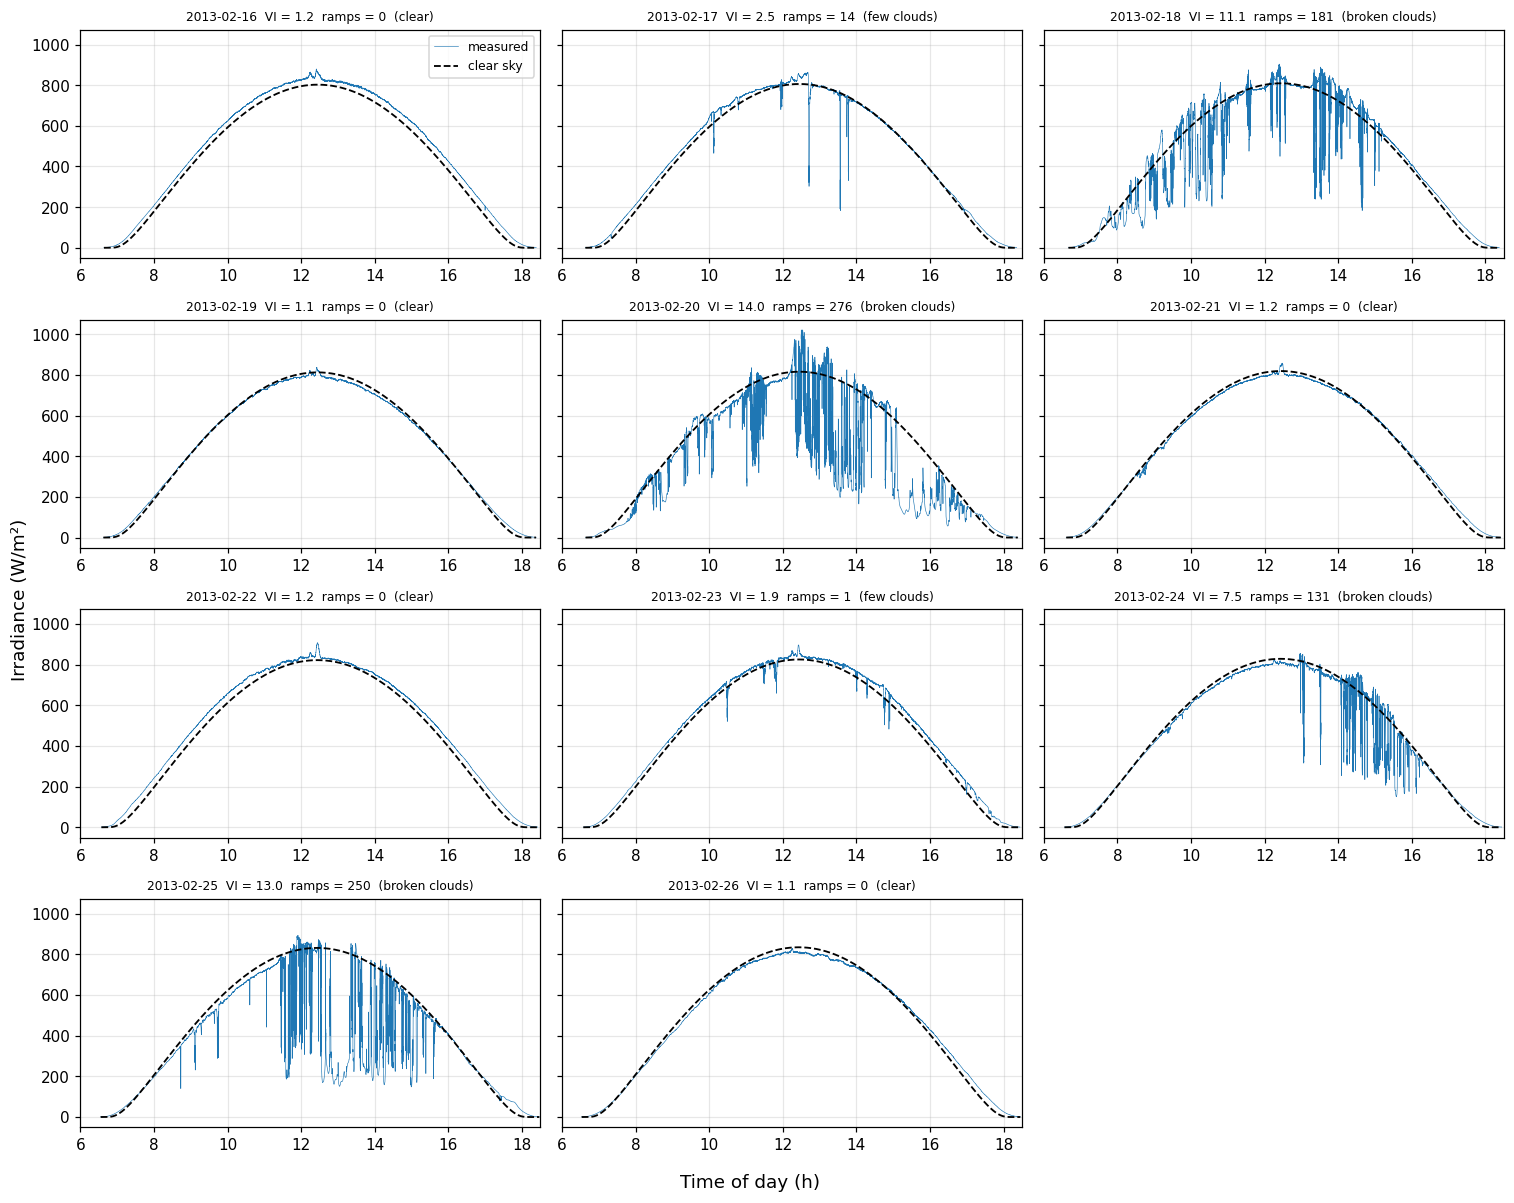

In [ ]:
# =====================================================================
# Each day: measured irradiance vs clear-sky curve
# =====================================================================
fig, axes = plt.subplots(4, 3, figsize=(14, 11), sharey=True)
for ax, day in zip(axes.ravel(), days):
    g = d1[d1.index.date == day]
    hours = g.index.hour + g.index.minute / 60 + g.index.second / 3600     # time of day in hours
    ax.plot(hours, g["G"], lw=0.4, label="measured")
    ax.plot(hours, g["G_clear"], lw=1.2, ls="--", color="k", label="clear sky")
    ax.set_title(f"{day}  VI = {daily.loc[day, 'VI']:.1f}  ramps = {daily.loc[day, 'ramp steps']}  ({daily.loc[day, 'type']})",
                 fontsize=8)
    ax.set_xlim(6, 18.5)
axes.ravel()[-1].axis("off")                        # 11 days, 12 panels
axes[0, 0].legend(fontsize=8)
fig.supxlabel("Time of day (h)"); fig.supylabel("Irradiance (W/m²)")
plt.tight_layout(); plt.show()

**What the plot shows.** The curves agree with the statistics: on clear days the measured irradiance lies on the clear-sky curve, and on broken-cloud days it drops far below it again and again. The plot also suggests three patterns, which we test with numbers in the next steps:

1. On broken-cloud days, irradiance seems to switch between two levels: close to clear sky (sun visible) and much lower (sun blocked). *Tested below with the clear-sky index histogram: only the "sun visible" level is distinct; when the sun is blocked, the level varies widely (20–70 % of clear sky).*
2. Clouds appear mainly around midday and in the afternoon; mornings are mostly smooth. *Tested below with ramps per hour: confirmed, with a peak at 13:00–15:00. Part of the effect comes from the high sun at midday, which makes each cloud cause a larger drop.*
3. On 20 Feb after about 15:00, irradiance stays low for a long time without large jumps, which suggests continuous cloud cover. Such periods are cloudy but produce few ramps, so a cloudy period is not always a ramp period.

### When in the day do ramps happen?

**Goal:** find out at what time of day ramps occur.

We count the ramp steps in each hour of the day, in two ways:

1. **In irradiance:** 10-s changes larger than 80 W/m², i.e. the ramps as we defined them.
2. **In the clear-sky index:** 10-s changes larger than 0.1 (10 % of the clear-sky value, about 80 W/m² at noon). This removes the daily rise and fall of the sun.

**Why both?** In the morning the sun is low and irradiance is small, so even a thick cloud causes only a small drop in W/m², and it may stay below 80 W/m². Fewer ramps in the morning could therefore mean fewer clouds, or just smaller drops. The clear-sky index tells the two apart: if morning ramps appear in the clear-sky index but not in irradiance, the clouds were there and only their drops were small.

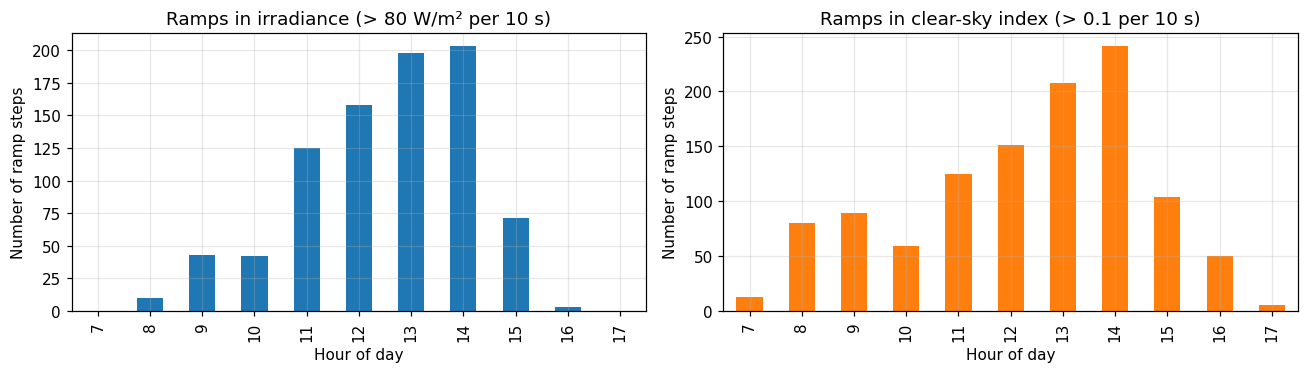

Ramps in irradiance: 853 in total, 93 % between 10:00 and 16:00
Ramps in clear-sky index: 1125 in total, 79 % between 10:00 and 16:00


In [ ]:
# =====================================================================
# When in the day do ramps happen?
# =====================================================================
# Left:  ramps in irradiance G (10-s change > THRESHOLD = 80 W/m²)
# Right: ramps in the clear-sky index csi (10-s change > 0.1)
#        csi removes the daily rise and fall of the sun. 0.1 = 10 % of the clear-sky value,
#        which is about 80 W/m² around noon, so both definitions are similar at midday.
CSI_THRESHOLD = 0.1

# ---- 10-s changes of G for all days (already computed in the daily statistics cell) ----
dG_all = pd.concat(changes.values())

# ---- 10-s changes of csi for all days (csi exists only when the sun is above 10°) ----
dcsi = []
for day in days:
    c10 = d1.loc[d1.index.date == day, "csi"].resample("10s").mean().dropna()
    ok  = c10.index.to_series().diff() == pd.Timedelta(seconds=10)   # only real neighbouring steps
    dcsi.append(c10.diff()[ok])
dcsi_all = pd.concat(dcsi)

# ---- Count ramp steps per hour of the day ----
hours = range(7, 18)                                                  # daylight hours
count_G   = pd.Series(dG_all[dG_all.abs() > THRESHOLD].index.hour).value_counts().reindex(hours, fill_value=0)
count_csi = pd.Series(dcsi_all[dcsi_all.abs() > CSI_THRESHOLD].index.hour).value_counts().reindex(hours, fill_value=0)

# ---- Plot ----
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
count_G.plot(kind="bar", ax=ax[0], color="tab:blue")
ax[0].set_title(f"Ramps in irradiance (> {THRESHOLD} W/m² per 10 s)")
count_csi.plot(kind="bar", ax=ax[1], color="tab:orange")
ax[1].set_title(f"Ramps in clear-sky index (> {CSI_THRESHOLD} per 10 s)")
for a in ax:
    a.set_xlabel("Hour of day"); a.set_ylabel("Number of ramp steps")
plt.tight_layout(); plt.show()

# ---- Share of ramps between 10:00 and 16:00 (about half of the daylight hours) ----
for name, c in [("irradiance", count_G), ("clear-sky index", count_csi)]:
    print(f"Ramps in {name}: {c.sum()} in total, {100 * c.loc[10:15].sum() / c.sum():.0f} % between 10:00 and 16:00")

**When do ramps happen?** We counted ramp steps per hour in two ways: in irradiance (change > 80 W/m² per 10 s) and in the clear-sky index (change > 0.1 per 10 s), which removes the daily rise and fall of the sun.

- In irradiance, **93 %** of the 853 ramp steps occur between 10:00 and 16:00, with a peak at 13:00–15:00.
- In the clear-sky index, this share drops to **79 %**: many cloud changes also occur in the morning (169 ramp steps at 8–9 h, against 53 in irradiance), but with the sun still low their drops in W/m² are small.
- The peak at 13:00–15:00 remains in both counts, so clouds were indeed most frequent in the early afternoon.

Two effects therefore combine: clouds are more frequent around midday and in the early afternoon, and the high sun at that time makes each cloud produce a larger change in irradiance. For the forecasting study this means that the time of day carries information about the chance of a ramp, and that a threshold in W/m² mainly selects the large midday ramps, which are also the most relevant for grid operation.

### How large are the changes, and at which time scale?

**Goal:** see how big irradiance changes are over 1 s, 10 s and 60 s on the broken-cloud days, and how rare the large changes are.

For each time scale we average the irradiance over that interval (1 s = raw data) and take the change from one interval to the next, $\Delta G_t = G_t - G_{t-\Delta t}$. We then look at:

- **Percentiles** of $|\Delta G|$: the typical change (50th percentile) and the large ones (95th, 99th, maximum).
- **Excess kurtosis:** how heavy the tails of the distribution are. A normal (Gaussian) distribution has 0; a large value means that most changes are tiny but a few are very large, which is typical for ramps.
- **Histogram** of $\Delta G$ on a log scale, so the rare large changes are visible next to the many small ones.

This shows whether the 10-s resolution of the forecasting study keeps the large changes, or whether averaging hides them.

,1 s,10 s,60 s
number of changes,170138.0,17014.0,2835.0
median |ΔG|,0.1,0.9,4.0
95th pct |ΔG|,11.8,79.1,181.4
99th pct |ΔG|,67.2,208.7,318.1
max |ΔG|,393.8,475.0,483.7
excess kurtosis,120.3,30.8,12.4


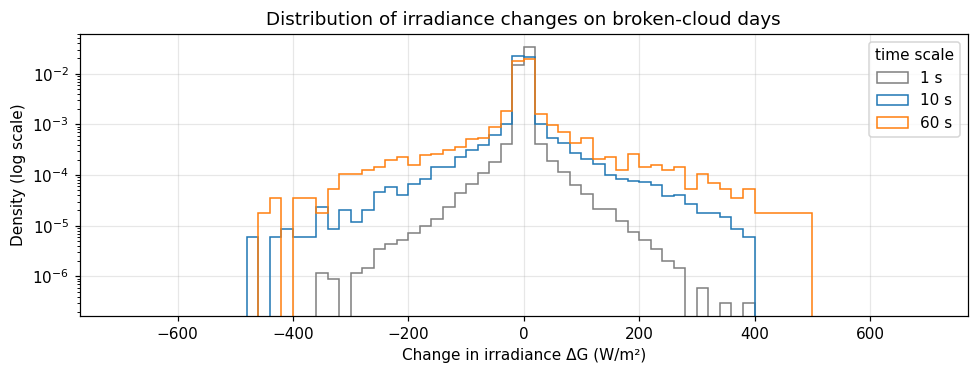

In [ ]:
# =====================================================================
# Size of irradiance changes at 1 s, 10 s and 60 s (broken-cloud days)
# =====================================================================
broken_days = list(daily.index[daily["type"] == "broken clouds"])      # 18, 20, 24, 25 Feb


def changes_at(step_s):
    """|ΔG| between neighbouring intervals of step_s seconds, on the broken-cloud days."""
    out = []
    for day in broken_days:
        g = d1.loc[d1.index.date == day, "G"]
        if step_s > 1:
            g = g.resample(f"{step_s}s").mean().dropna()                # average over each interval
        ok = g.index.to_series().diff() == pd.Timedelta(seconds=step_s) # only real neighbours (no gaps)
        out.append(g.diff()[ok])                                        # change from one interval to the next
    return pd.concat(out)


SCALES = [1, 10, 60]                                                    # time scales in seconds
dG = {s: changes_at(s) for s in SCALES}

# ---- Table: typical and large changes at each time scale ----
table = pd.DataFrame({
    f"{s} s": {
        "number of changes":   len(dG[s]),
        "median |ΔG|":         dG[s].abs().median(),
        "95th pct |ΔG|":       dG[s].abs().quantile(0.95),
        "99th pct |ΔG|":       dG[s].abs().quantile(0.99),
        "max |ΔG|":            dG[s].abs().max(),
        "excess kurtosis":     dG[s].kurt(),          # 0 for a normal distribution
    } for s in SCALES})
display(table.round(1))

# ---- Histogram of the changes (log scale shows the rare large changes) ----
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(-700, 701, 20)
for s, c in zip(SCALES, ["tab:gray", "tab:blue", "tab:orange"]):
    ax.hist(dG[s], bins=bins, density=True, histtype="step", lw=1.5, color=c, label=f"{s} s")
ax.set_yscale("log")
ax.set_xlabel("Change in irradiance ΔG (W/m²)"); ax.set_ylabel("Density (log scale)")
ax.set_title("Distribution of irradiance changes on broken-cloud days")
ax.legend(title="time scale"); plt.tight_layout(); plt.show()

**Results: size of the changes**

| | 1 s | 10 s | 60 s |
|---|---|---|---|
| median \|ΔG\| (W/m²) | 0.1 | 0.9 | 4.0 |
| 95th percentile | 12 | 79 | 181 |
| 99th percentile | 67 | 209 | 318 |
| maximum | 394 | 475 | 484 |
| excess kurtosis | 120 | 31 | 12 |

- **Most of the time almost nothing changes.** Even on broken-cloud days, the median change is below 1 W/m² over 10 s.
- **The rare changes are very large.** The excess kurtosis is far above 0 (the value for a normal distribution) at every time scale: most changes are tiny, but a few reach 400–480 W/m². This is the situation in which an MSE-trained model learns to predict "almost no change" and misses the rare ramps.
- **A cloud edge passes within seconds.** The largest change is already 394 W/m² within one second and 475 W/m² within 10 s, almost the same as within a full minute (484 W/m²). A full sun-to-shade transition is therefore complete within about 10 s. The 10-s resolution keeps the size of the ramps, while a 1-min resolution would place a whole ramp inside one step and lose its timing.
- **The threshold is consistent.** The 95th percentile of 10-s changes over all four broken-cloud days is 79 W/m², almost equal to our threshold of 80 W/m², which was computed from the training days only.

### Does irradiance switch between two levels?

**Goal:** test whether, on broken-cloud days, irradiance mostly stays at one of two levels (sun visible or sun blocked) and spends little time in between.

We plot the histogram of the clear-sky index $csi = G / G_{clear}$ for the broken-cloud days and, for comparison, the clear days. If irradiance switches between two levels, the broken-cloud histogram shows **two peaks**: one near $csi \approx 1$ (sun visible) and one at low values (sun blocked), with a valley between them. We locate the two peaks and the valley from the histogram itself, and report how much of the time falls on each side of the valley.

Peak 'sun visible': csi ≈ 0.97
Peak 'sun blocked': csi ≈ 0.31
Valley between them: csi ≈ 0.75
Time with csi below the valley (sun blocked): 20 %
Time in the band ±0.1 around the valley (in between): 5 %


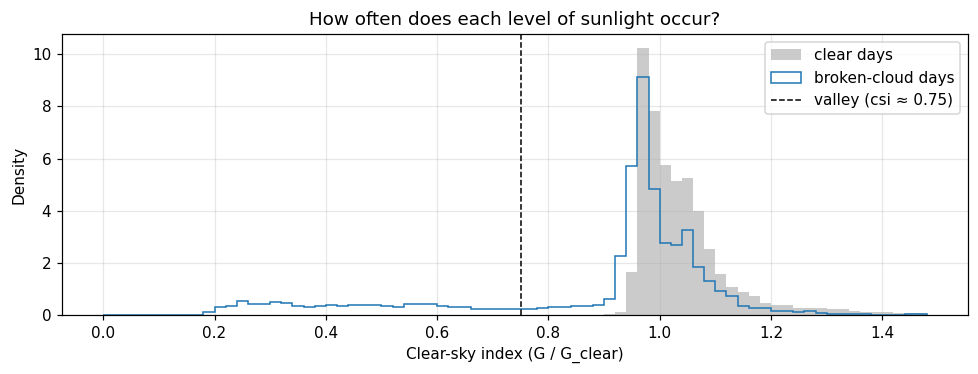

In [ ]:
# =====================================================================
# Histogram of the clear-sky index: one level or two?
# =====================================================================
bins    = np.arange(0, 1.5, 0.02)
centres = (bins[:-1] + bins[1:]) / 2

csi_broken = d1.loc[np.isin(d1.index.date, broken_days), "csi"].dropna()
clear_days = list(daily.index[daily["type"] == "clear"])
csi_clear  = d1.loc[np.isin(d1.index.date, clear_days), "csi"].dropna()

# ---- Find the two peaks and the valley between them (broken-cloud days) ----
hist, _ = np.histogram(csi_broken, bins=bins, density=True)
smooth  = pd.Series(hist).rolling(3, center=True, min_periods=1).mean().to_numpy()   # light smoothing
i_high  = int(np.argmax(smooth))                                   # main peak (sun visible, near 1)
low     = centres < centres[i_high] - 0.3                          # look for a second peak clearly lower
i_low   = int(np.argmax(np.where(low, smooth, -1)))                # second peak (sun blocked)
i_valley = i_low + int(np.argmin(smooth[i_low:i_high]))            # lowest point between the two peaks
valley  = centres[i_valley]

print(f"Peak 'sun visible': csi ≈ {centres[i_high]:.2f}")
print(f"Peak 'sun blocked': csi ≈ {centres[i_low]:.2f}")
print(f"Valley between them: csi ≈ {valley:.2f}")
print(f"Time with csi below the valley (sun blocked): {100 * (csi_broken < valley).mean():.0f} %")
print(f"Time in the band ±0.1 around the valley (in between): "
      f"{100 * ((csi_broken > valley - 0.1) & (csi_broken < valley + 0.1)).mean():.0f} %")

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(csi_clear,  bins=bins, density=True, alpha=0.4, color="tab:gray", label="clear days")
ax.hist(csi_broken, bins=bins, density=True, histtype="step", lw=1.8, color="tab:blue", label="broken-cloud days")
ax.axvline(valley, color="k", ls="--", lw=1, label=f"valley (csi ≈ {valley:.2f})")
ax.set_xlabel("Clear-sky index (G / G_clear)"); ax.set_ylabel("Density")
ax.set_title("How often does each level of sunlight occur?")
ax.legend(); plt.tight_layout(); plt.show()

**Results: one level or two?**

- On the broken-cloud days, the clear-sky index has one strong peak at **csi ≈ 0.97**, close to the peak of the clear days. About **80 %** of the time lies above csi = 0.75, so even on the cloudiest days the sun is visible most of the time.
- When the sun is blocked, there is **no clear second level**. The values below 0.75 form a broad, flat plateau between about 0.2 and 0.7, with only a weak bump at 0.31 (about 20 times lower than the main peak). The irradiance under a cloud can be anywhere between 20 % and 70 % of clear sky, depending on the cloud.
- The minimum between the two (csi ≈ 0.75) is shallow, so it does not separate two distinct states.

**Conclusion.** Irradiance is usually close to the clear-sky level and drops away from it about 20 % of the time, but the depth of each drop varies widely. This corrects the impression from the day plots of a fixed "blocked" level: a forecasting model has to predict both *when* a ramp happens and *how deep* it goes.

### Are the ramps real? Check with an independent sensor

**Goal:** make sure the ramps are real changes in sunlight and not noise or errors of the irradiance sensor.

The current of PV module 2 (`PV_2_GT_I`) is measured by a separate device. The current of a PV module is proportional to the sunlight it receives, so if a cloud blocks the sun, both the irradiance and the module current should drop at the same moment. Sensor noise, on the other hand, would appear in one device only.

On the broken-cloud days we compare the 10-s changes of both signals:
- the **correlation** between the changes of irradiance and of the module current;
- at every **ramp step** (irradiance change > 80 W/m²): whether the module current changed **in the same direction**;
- a **close-up** of one cloudy period with both signals together.

Correlation of 10-s changes (irradiance vs module current): 0.947
Ramp steps: 838   module current moved in the same direction: 98.8 %


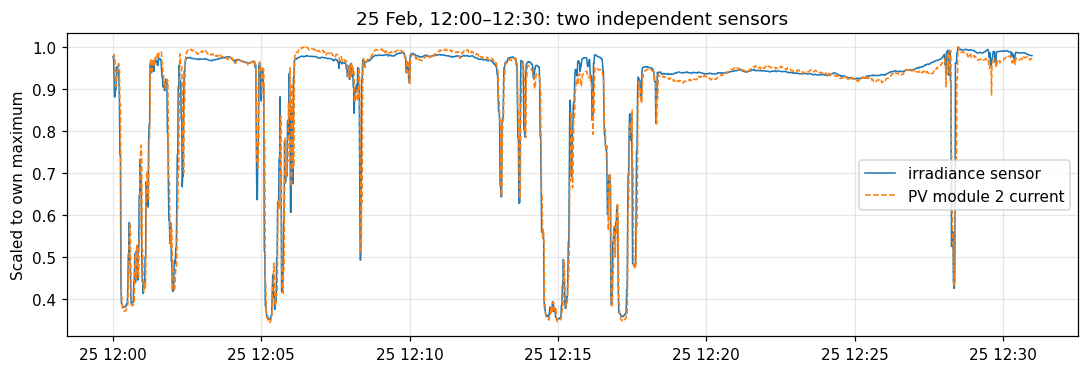

In [ ]:
# =====================================================================
# Are the ramps real? Compare with an independent sensor (PV module 2 current)
# =====================================================================
dG_list, dI_list = [], []
for day in broken_days:
    g10 = d1.loc[d1.index.date == day, ["G", "PV_2_GT_I"]].resample("10s").mean().dropna()
    ok  = g10.index.to_series().diff() == pd.Timedelta(seconds=10)      # only real neighbouring steps
    dG_list.append(g10["G"].diff()[ok])                                  # 10-s change of irradiance (W/m²)
    dI_list.append(g10["PV_2_GT_I"].diff()[ok])                          # 10-s change of module current (A)
dG_b, dI_b = pd.concat(dG_list), pd.concat(dI_list)

# ---- 1) Do the changes of the two sensors go together? ----
print(f"Correlation of 10-s changes (irradiance vs module current): {dG_b.corr(dI_b):.3f}")

# ---- 2) At each ramp step: did the module current move the same way? ----
ramp = dG_b.abs() > THRESHOLD
same = np.sign(dG_b[ramp]) == np.sign(dI_b[ramp])
print(f"Ramp steps: {ramp.sum()}   module current moved in the same direction: {100 * same.mean():.1f} %")

# ---- 3) Close-up of one cloudy period: both signals, each scaled to its own maximum ----
win = d1.loc["2013-02-25 12:00":"2013-02-25 12:30", ["G", "PV_2_GT_I"]]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(win.index, win["G"] / win["G"].max(), lw=1, label="irradiance sensor")
ax.plot(win.index, win["PV_2_GT_I"] / win["PV_2_GT_I"].max(), lw=1, ls="--", label="PV module 2 current")
ax.set_ylabel("Scaled to own maximum"); ax.set_title("25 Feb, 12:00–12:30: two independent sensors")
ax.legend(); plt.tight_layout(); plt.show()

**Results: the ramps are real.**
On the broken-cloud days, the 10-s changes of the irradiance sensor and of the PV module 2 current have a correlation of 0.947. At 98.8 % of the 838 ramp steps, the module current changed in the same direction at the same time. The close-up of 25 Feb (12:00–12:30) shows that both devices record the same drops, to the same depth (about 35–40 % of their maximum), and recover together. Since two separate devices see the same events, the ramps are real changes in sunlight and not noise of the irradiance sensor. Together with the absence of ramps on clear days and their concentration around midday, this strongly supports that the ramps are caused by clouds.

### Ramp events

**Goal:** describe the ramps as events: how many there are, how large they are, whether drops differ from rises, and how long the sun stays blocked.

**From ramp steps to events.** A ramp step is a 10-s change larger than 80 W/m². One cloud edge can produce two or three ramp steps in a row (e.g. −150 and then −120 W/m²). We therefore join consecutive ramp steps in the same direction into one **ramp event**:
- **direction:** down (sun becomes blocked) or up (sun returns);
- **size:** the total change of the event, $|\sum \Delta G|$ over its ramp steps (W/m²);
- **length:** the number of 10-s steps the event takes.

**Shade duration.** For every down event, we measure the time until the next up event on the same day: how long the sun stayed blocked.

**Drops vs rises.** We compare the sizes of down and up events with a Mann–Whitney U test, which checks whether one group tends to have larger values than the other without assuming a normal distribution (useful here, since the sizes are far from normal). A p-value below 0.05 means the difference is unlikely to be chance.

Ramp events: 648   (down: 322, up: 326)
Events per day:
day
2013-02-17     10
2013-02-18    154
2013-02-20    209
2013-02-23      1
2013-02-24     94
2013-02-25    180

Size (W/m²)        median   90th pct    max
  down                166        389     549
  up                  167        393     577
  Mann–Whitney U test, down vs up: p = 0.741

Events completed within one 10-s step: down 71 %, up 73 %

Shade duration (s): median 20   shorter than 1 min: 73 %   shorter than 5 min: 95 %


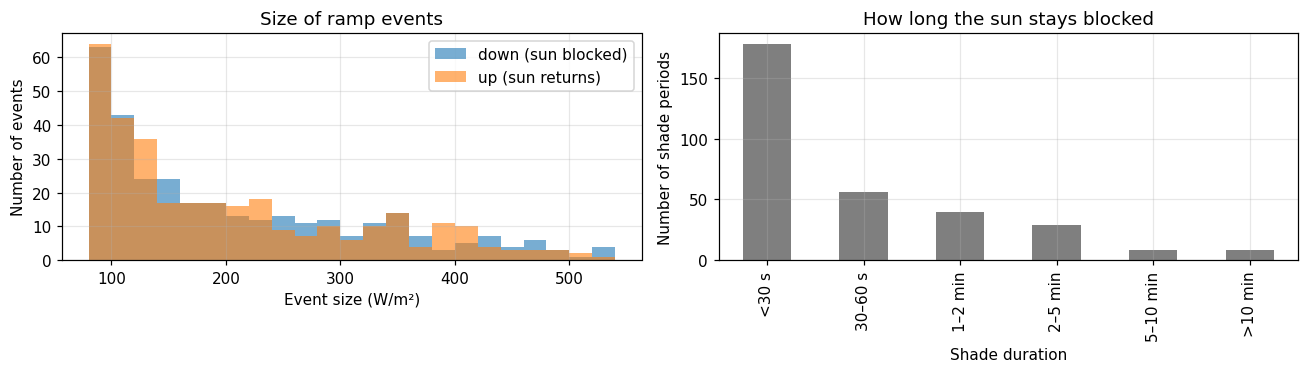

In [ ]:
# =====================================================================
# Ramp events: join consecutive ramp steps in the same direction
# =====================================================================
from scipy.stats import mannwhitneyu

events = []
for day in days:
    s = changes[day]                                   # 10-s changes of this day (gaps already removed)
    r = s[s.abs() > THRESHOLD]                         # only the ramp steps
    if r.empty:
        continue
    sign = np.sign(r)
    # A new event starts when the previous ramp step is not the directly preceding 10-s step,
    # or when the direction changes (down → up or up → down)
    new_event = (r.index.to_series().diff() != pd.Timedelta(seconds=10)) | (sign != sign.shift())
    for _, e in r.groupby(new_event.cumsum().to_numpy()):
        events.append({
            "day":         day,
            "start":       e.index[0] - pd.Timedelta(seconds=10),   # beginning of the first step
            "end":         e.index[-1],                             # end of the last step
            "direction":   "down" if e.iloc[0] < 0 else "up",
            "size (W/m²)": abs(e.sum()),                            # total change of the event
            "steps":       len(e),                                  # length in 10-s steps
        })
events = pd.DataFrame(events)

# ---- Shade duration: from each down event to the next up event on the same day ----
shade = []
for day, ev in events.groupby("day"):
    ev = ev.sort_values("start")
    for _, down in ev[ev["direction"] == "down"].iterrows():
        nxt = ev[(ev["direction"] == "up") & (ev["start"] >= down["end"])]
        if not nxt.empty:                                           # skip if the sun did not return that day
            shade.append((nxt.iloc[0]["start"] - down["end"]).total_seconds())
shade = pd.Series(shade)

# ---- Summary ----
down = events.loc[events["direction"] == "down", "size (W/m²)"]
up   = events.loc[events["direction"] == "up",   "size (W/m²)"]
p    = mannwhitneyu(down, up).pvalue

print(f"Ramp events: {len(events)}   (down: {len(down)}, up: {len(up)})")
print(f"Events per day:\n{events.groupby('day').size().to_string()}\n")
print(f"Size (W/m²)        median   90th pct    max")
print(f"  down             {down.median():6.0f}   {down.quantile(0.9):8.0f}   {down.max():5.0f}")
print(f"  up               {up.median():6.0f}   {up.quantile(0.9):8.0f}   {up.max():5.0f}")
print(f"  Mann–Whitney U test, down vs up: p = {p:.3f}\n")
one_step = events.groupby("direction")["steps"].apply(lambda x: 100 * (x == 1).mean())
print(f"Events completed within one 10-s step: down {one_step['down']:.0f} %, up {one_step['up']:.0f} %\n")
print(f"Shade duration (s): median {shade.median():.0f}   "
      f"shorter than 1 min: {100 * (shade < 60).mean():.0f} %   shorter than 5 min: {100 * (shade < 300).mean():.0f} %")

# ---- Plots ----
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.arange(THRESHOLD, 560, 20)
ax[0].hist(down, bins=bins, alpha=0.6, label="down (sun blocked)")
ax[0].hist(up,   bins=bins, alpha=0.6, label="up (sun returns)")
ax[0].set_xlabel("Event size (W/m²)"); ax[0].set_ylabel("Number of events")
ax[0].set_title("Size of ramp events"); ax[0].legend()

edges  = [0, 30, 60, 120, 300, 600, np.inf]
labels = ["<30 s", "30–60 s", "1–2 min", "2–5 min", "5–10 min", ">10 min"]
pd.cut(shade, edges, labels=labels, right=False).value_counts().reindex(labels).plot(
    kind="bar", ax=ax[1], color="tab:gray")
ax[1].set_xlabel("Shade duration"); ax[1].set_ylabel("Number of shade periods")
ax[1].set_title("How long the sun stays blocked")
plt.tight_layout(); plt.show()

**Results: ramp events**

- **Number.** Joining consecutive ramp steps gives 648 ramp events: 322 down and 326 up. Almost all (637) occur on the four broken-cloud days.
- **Drops vs rises.** Down and up events have the same size (median 166 vs 167 W/m²; Mann–Whitney U test, p = 0.74). Clouds remove and return the same amount of light; we find no evidence that drops are larger or faster than rises.
- **Size.** Event sizes range from 80 to about 550 W/m² (median about 165 W/m²), so the depth of a ramp varies widely, in line with the clear-sky index results.
- **Speed.** About 72 % of the events are completed within a single 10-s step. The timing of a ramp is therefore decided at the 10-s level, and a forecast that is one step early or late misses it.
- **Shade duration.** The sun stays blocked for a median of only 20 s; 73 % of the shade periods are shorter than 1 minute and 95 % shorter than 5 minutes. With a forecast horizon of 60 s, most shadows begin and end within one forecast, so a good forecast must predict a short dip rather than a lasting step down. Persistence, which keeps the current value, is especially poor here.

### Predictability: do ramps come in clusters?

**Goal:** find out how much the past tells us about the next minute, i.e. what a model can learn from past irradiance alone.

We look at the broken-cloud days at 10-s resolution in two ways:

1. **Autocorrelation** of the 10-s changes $\Delta G_t$ and of their size $|\Delta G_t|$, for lags from 10 s to 30 min. The autocorrelation at lag $k$ is the correlation between a value and the value $k$ steps later:
   $$\rho(k) = \text{corr}(x_t,\; x_{t+k})$$
   - If $\rho$ of $\Delta G$ is close to 0, the **direction** of the next change cannot be predicted from past changes.
   - If $\rho$ of $|\Delta G|$ is clearly above 0, **large changes follow large changes**: calm periods and restless periods each last for a while (clustering).

2. **Chance of a ramp in the next minute**, depending on the recent past:
   $$P(\text{ramp in next 60 s} \mid \text{ramps in last 5 min})$$
   If this chance is much higher after recent ramps than after a calm period, recent variability is useful information for forecasting.

Correlations are computed within each day only, so no pair of values crosses from one day to the next.

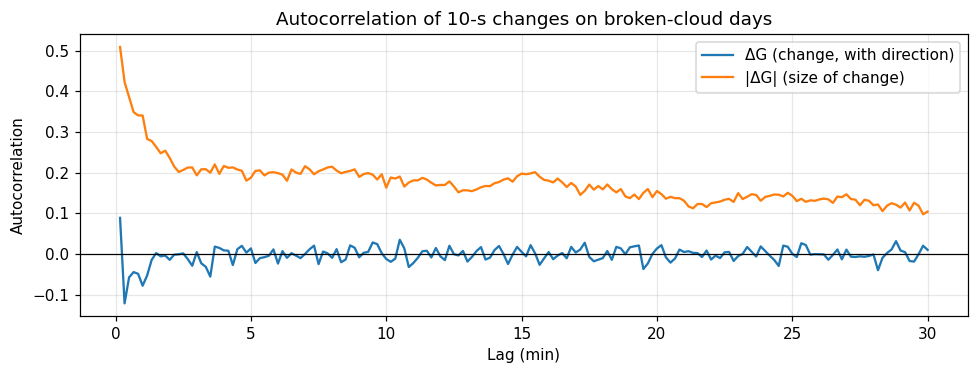

Lag 10 s:  ΔG +0.09   |ΔG| +0.51
Lag 5 min: ΔG +0.01   |ΔG| +0.19

Overall chance of a ramp in the next 60 s: 14 %


,chance of a ramp in next 60 s,number of cases
ramps in last 5 min,,
0,3.0,12124
1–2,30.0,1386
3–5,39.0,1440
more than 5,55.0,1924


In [ ]:
# =====================================================================
# Predictability A: autocorrelation and clustering of ramps (broken-cloud days)
# =====================================================================
# Regular 10-s series per day; missing steps stay NaN, so no change crosses a gap
dG_days = {d: d1.loc[d1.index.date == d, "G"].resample("10s").mean().diff() for d in broken_days}


def pooled_acf(series_list, lags):
    """Autocorrelation at each lag, pooling all days but never pairing values from different days."""
    out = []
    for k in lags:
        a = np.concatenate([s.to_numpy()[:-k] for s in series_list])    # value at time t
        b = np.concatenate([s.to_numpy()[k:]  for s in series_list])    # value at time t + k
        m = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.corrcoef(a[m], b[m])[0, 1])
    return np.array(out)


lags = np.arange(1, 181)                                             # 10 s ... 30 min
acf_dG  = pooled_acf(list(dG_days.values()), lags)                   # direction + size of changes
acf_abs = pooled_acf([s.abs() for s in dG_days.values()], lags)      # size of changes only

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lags * 10 / 60, acf_dG,  label="ΔG (change, with direction)")
ax.plot(lags * 10 / 60, acf_abs, label="|ΔG| (size of change)")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Lag (min)"); ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of 10-s changes on broken-cloud days")
ax.legend(); plt.tight_layout(); plt.show()
print(f"Lag 10 s:  ΔG {acf_dG[0]:+.2f}   |ΔG| {acf_abs[0]:+.2f}")
print(f"Lag 5 min: ΔG {acf_dG[29]:+.2f}   |ΔG| {acf_abs[29]:+.2f}")

# ---- Chance of a ramp in the next 60 s, depending on the number of ramps in the last 5 min ----
rows = []
for d, s in dG_days.items():
    ramp   = (s.abs() > THRESHOLD).astype(float)                     # 1 = ramp step, 0 = no ramp
    ramp[s.isna()] = np.nan                                          # unknown where data are missing
    past   = ramp.rolling(30, min_periods=30).sum()                  # ramps in the last 5 min (30 steps)
    future = ramp[::-1].rolling(6, min_periods=6).max()[::-1].shift(-1)   # any ramp in the next 60 s
    rows.append(pd.DataFrame({"past": past, "future": future}).dropna())
pf = pd.concat(rows)

groups = pd.cut(pf["past"], [-0.5, 0.5, 2.5, 5.5, np.inf], labels=["0", "1–2", "3–5", "more than 5"])
table = pf.groupby(groups, observed=True)["future"].agg(["mean", "size"])
table.columns = ["chance of a ramp in next 60 s", "number of cases"]
table.index.name = "ramps in last 5 min"
print(f"\nOverall chance of a ramp in the next 60 s: {100 * pf['future'].mean():.0f} %")
display((table.assign(**{"chance of a ramp in next 60 s": 100 * table.iloc[:, 0]})).round(0))

**Results: what can be predicted from the past?**

- **Direction of the next change: hardly predictable.** The autocorrelation of the 10-s changes ΔG is only +0.09 at 10 s and slightly negative (about −0.1) between 20 s and 1 min, after which it stays close to 0. The small negative part fits the short shadows found earlier: after a drop, the sun often returns within 20–60 s. Beyond about one minute, past changes do not tell whether the next change will go up or down.
- **Restless periods last.** The size of the changes |ΔG| has an autocorrelation of 0.51 at 10 s, which stays around 0.2 for 15 minutes and is still about 0.1 after 30 minutes. Large changes follow large changes, and calm follows calm (volatility clustering).
- **Recent ramps strongly raise the chance of a new ramp.** Overall, a ramp occurs in the next 60 s in 14 % of the cases. After 5 calm minutes this chance is only 3 %, but after more than 5 ramps in the last 5 minutes it rises to 55 %, about 18 times higher.

**Conclusion.** From past irradiance, a model can learn *whether* a ramp is likely in the next minute, but hardly *when exactly* it will happen or *in which direction*. This explains why an MSE-trained model smooths its forecasts during restless periods, and it suggests that measures of recent variability are useful inputs, and that forecasting the probability of a ramp is a realistic target.


### Predictability: how fast does the past become outdated?

**Goal:** see how quickly the current value stops being a good forecast, on clear and on broken-cloud days.

Persistence uses the current value as the forecast for every lead time $h$: $\hat G_{t+h} = G_t$. Its error,

$$\text{RMSE}(h) = \sqrt{\text{mean}\big[(G_{t+h} - G_t)^2\big]},$$

shows how much the irradiance changes within $h$. We compute it for leads from 10 s to 10 min, separately for clear and broken-cloud days. This is also the reference that our forecasting models must beat.

,clear days,broken-cloud days
lead (s),,
10,0.9,40.8
20,1.5,60.2
30,2.1,71.9
60,3.5,93.9
120,6.3,111.6
300,14.0,130.8
600,26.7,138.5


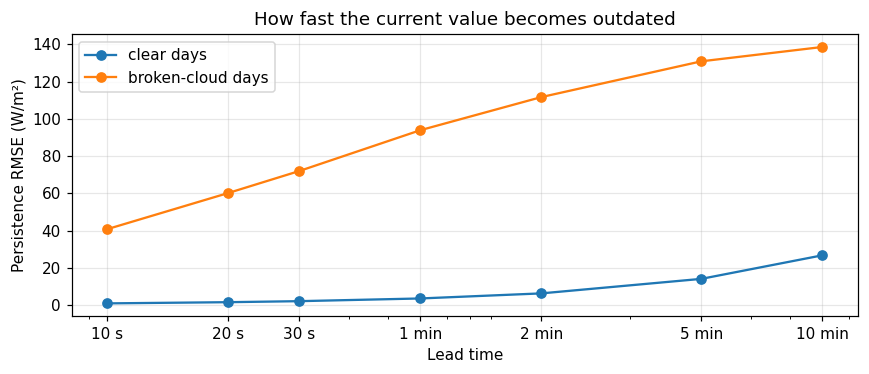

In [ ]:
# =====================================================================
# Predictability B: persistence error vs lead time (clear vs broken-cloud days)
# =====================================================================
LEADS = [10, 20, 30, 60, 120, 300, 600]                              # seconds


def persistence_rmse(day_list, lead_s):
    """RMSE of G(t + lead) - G(t), within each day only (10-s averages)."""
    err = []
    for d in day_list:
        g = d1.loc[d1.index.date == d, "G"].resample("10s").mean()   # regular grid, NaN for gaps
        err.append((g.shift(-lead_s // 10) - g).dropna())
    return np.sqrt((pd.concat(err) ** 2).mean())


res = pd.DataFrame({
    "clear days":         [persistence_rmse(clear_days,  h) for h in LEADS],
    "broken-cloud days":  [persistence_rmse(broken_days, h) for h in LEADS],
}, index=pd.Index(LEADS, name="lead (s)"))
display(res.round(1))

ax = res.plot(marker="o", figsize=(8, 3.5), logx=True)
ax.set_xticks(LEADS); ax.set_xticklabels(["10 s", "20 s", "30 s", "1 min", "2 min", "5 min", "10 min"])
ax.set_xlabel("Lead time"); ax.set_ylabel("Persistence RMSE (W/m²)")
ax.set_title("How fast the current value becomes outdated")
plt.tight_layout(); plt.show()

**Results: how fast the current value becomes outdated**

| Lead | 10 s | 20 s | 30 s | 1 min | 2 min | 5 min | 10 min |
|---|---|---|---|---|---|---|---|
| Clear days (W/m²) | 0.9 | 1.5 | 2.1 | 3.5 | 6.3 | 14.0 | 26.7 |
| Broken-cloud days (W/m²) | 40.8 | 60.2 | 71.9 | 93.9 | 111.6 | 130.8 | 138.5 |

- **Clear days:** persistence is almost perfect up to one minute (error below 4 W/m²). The error that appears at longer leads comes from the sun's daily rise and fall, not from clouds. A model can hardly improve on persistence here.
- **Broken-cloud days:** the error is already 41 W/m² at 10 s and more than doubles within one minute (94 W/m²). It then flattens (131 W/m² at 5 min, 139 W/m² at 10 min): after a few minutes, the current value has lost most of its information, in line with shade periods that last only about 20 s.

**Conclusion.** The forecast horizon of 10–60 s lies on the steepest part of the curve, where persistence becomes worse quickly but the past still carries information about the sky (restless periods last for minutes). This is where a forecasting model has the most room to improve. Beyond a few minutes, past irradiance alone carries little information, and seeing the approaching clouds (sky images or satellite data) would be needed.

## Summary of the exploration

We explored 11 complete days of 1-s irradiance data (16–26 Feb 2013) at Sohar University, Oman, with a focus on ramps. The site location and local time were confirmed with a clear-sky model (median ratio of measured to clear-sky irradiance near noon on clear days: 1.00).

### Main findings

1. **Three types of days.** The Variability Index separates the days into 5 clear days (VI 1.1–1.2), 2 days with few clouds (VI 1.9–2.5) and 4 broken-cloud days (VI 7.5–14), with large gaps between the groups. The share of time with the sun blocked (csi < 0.8) and the number of ramps rank the days in the same order.

2. **Ramps happen almost only on broken-cloud days.** With a ramp defined as a 10-s change larger than 80 W/m², clear days have no ramps, and 98 % of all ramp steps occur on the four broken-cloud days.

3. **The ramps are real.** An independent sensor (PV module 2 current) changed in the same direction at 98.8 % of the ramp steps, and the 10-s changes of both sensors have a correlation of 0.95.

4. **The daily total hides the cloud effect.** Broken-cloud days received at most 22 % less energy than clear days, while their VI was 7–14 times higher.

5. **Ramps are concentrated around midday and the early afternoon.** 93 % of the ramp steps occur between 10:00 and 16:00, with a peak at 13:00–15:00. Part of this comes from the high sun, which makes each cloud cause a larger drop; the peak remains when the sun's daily cycle is removed (79 % in the clear-sky index).

6. **Most of the time nothing changes, but the rare changes are very large.** The median 10-s change on broken-cloud days is below 1 W/m², while the largest reach 475 W/m² (excess kurtosis 31). A full sun-to-shade transition is complete within about 10 s.

7. **The sun is usually visible, but the shaded level varies.** On broken-cloud days the clear-sky index has one strong peak near 0.97; when the sun is blocked (about 20 % of the time), the level lies anywhere between 20 % and 70 % of clear sky.

8. **Ramp events are fast, balanced and short.** 648 ramp events were found (322 down, 326 up). Drops and rises have the same size (median 166 vs 167 W/m², p = 0.74). 72 % of the events are completed within one 10-s step, and the sun stays blocked for a median of only 20 s (73 % shorter than 1 min).

9. **The chance of a ramp is predictable, its timing hardly.** The direction of the next change cannot be predicted from past changes (autocorrelation close to 0 beyond 1 min), but restless periods last for tens of minutes (autocorrelation of |ΔG| about 0.2 for 15 min). The chance of a ramp in the next minute is 3 % after a calm 5 minutes and 55 % after more than 5 recent ramps.

10. **Persistence loses most of its value within 1–2 minutes on cloudy days.** Its error on broken-cloud days is 41 W/m² at 10 s, 94 W/m² at 1 min, and levels off at about 130–140 W/m² after 5–10 min. On clear days it stays below 4 W/m² up to 1 min.

### What this means for the forecasting study

| Decision | Based on |
|---|---|
| **Resolution of 10 s** | It keeps the full size of the ramps (findings 6 and 8); 1-min data would place a whole ramp inside one step. |
| **Horizon of 10–60 s** | The steepest part of the persistence error curve, where the past still carries information (findings 9 and 10). Beyond a few minutes, past irradiance alone is not enough. |
| **Ramp threshold of 80 W/m² per 10 s** | 95th percentile of 10-s changes on the broken-cloud training days (18 and 20 Feb). It replaces the earlier 60 W/m², which also included a day with few clouds; 60 W/m² is kept as a sensitivity check. |
| **Ramp evaluation on broken-cloud days, with a ±10 s tolerance** | Ramps occur almost only on these days (finding 2), and most are completed within one step (finding 8). |
| **Predicting the change from the current value (ΔG)** | On clear days persistence is almost perfect (finding 10), so the model should start from it and learn only the correction. |
| **Inputs to test: time of day and recent variability** | Ramps depend on the time of day (finding 5), and recent ramps strongly raise the chance of a new one (finding 9). |
| **Possible extensions: ramp probability and probabilistic forecasts** | Whether a ramp comes is predictable, but its timing and depth are not (findings 7 and 9). |
| **Day types for the split and the results** | Results are reported separately for clear and broken-cloud days (finding 1). |